## 07A Advanced Model for Claims: XGBoost

#### Purpose
- Develop an advanced classifier for claims (`CLAIM_IN_TERM` = 1 if the policy-year has at least one flood claim during its term) with **XGBoost** gradient-boosted trees.
- The model is judged **only as a classifier, with confusion matrices**: it flags the riskiest policy-years, and we count how many flagged and unflagged policy-years had a claim. It must flag better than the segment rule and the logistic-regression baseline (notebook 06a) on the same out-of-time test years (2021–2022). The twin notebooks with LightGBM (`07a_lightgbm_claim`) and random forest (`07a_random_forest_claim`) use the same data, folds, cut-off rules and outputs, so all three can be compared directly.

#### Why gradient boosting
Logistic regression adds up one straight-line effect per feature. Flood risk is not built that way: zone V matters more for an old building on a slab, a high storm wind matters more below the base flood elevation, and price changes matter differently for new and long-standing policies. Gradient boosting builds hundreds of small decision trees, each correcting the errors of the ones before, so it finds these **non-linear effects and interactions** without our writing them out. XGBoost grows each tree **level by level** up to a fixed depth (`max_depth`), with L1/L2 penalties on the leaf values. With `tree_method="hist"` and `enable_categorical=True` it bins the numbers and reads the categories natively.

#### How we judge the model: the confusion matrix only
The model gives every policy-year a **risk score**. A cut-off turns the score into a yes/no flag, and the flags against the actual outcomes give one confusion matrix:

|  | Claim ($y=1$) | No claim ($y=0$) |
|---|---|---|
| **Flagged** (score ≥ cut-off) | TP | FP |
| **Not flagged** | FN | TN |

$$\text{Accuracy} = \frac{TP+TN}{n} \qquad \text{Precision} = \frac{TP}{TP+FP} \qquad \text{Recall} = \frac{TP}{TP+FN} \qquad F_1 = \frac{2\cdot\text{Precision}\cdot\text{Recall}}{\text{Precision}+\text{Recall}} \qquad \text{Lift} = \frac{\text{Precision}}{\text{claim rate}}$$

Everything in this notebook is read from confusion matrices: the tuning metric, the choice of the cut-off, the test results, and the curves (each point of the ROC and precision–recall curves is one confusion matrix). **Log loss, Brier score, calibration and expected claims are not used**: the scores rank policy-years, and are not read as probabilities.

#### Steps:
1. Settings, the claim population and the weighted training sample
2. Benchmark: the segment rule
3. Tree preprocessing (missing values and categories)
4. Tune on recall in the riskiest 10%, choose the number of trees and the F1-best cut-off, train
5. Out-of-time test results: cut-offs, confusion matrices, precision and recall by flagged share, ROC curve
6. Feature importance and SHAP: why policy-years are flagged
7. Save the model and results
8. Our findings

#### Authors
Organized and prepared by Sebastian Carino, Ma. Loisa Celorico, Cyrill Agustin, John Navarro, and Justino Rotairo III.

- **Date Created:** 2026-11-17
- **Date Modified:** 2026-11-17

### Section 0. Load the libraries and working directory
Use the same setup cell as notebook 02 (repo root, data folders, reports folder), so the notebook runs on every teammate's machine.

`lightgbm` and `xgboost` are not yet in `requirements.txt`. Install them once with `pip install lightgbm xgboost`; on a Mac both also need OpenMP (`brew install libomp`).

#### 0.1 Imports, paths and random seed

In [1]:
%load_ext autoreload
%autoreload 2

# Find the repo root from any folder, so `src` can be imported
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import os
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb

from src.paths import DOCS, INTERIM, PROCESSED, RAW, REPORTS, ensure_dirs
from src.db import connect, scalar
from src.features import apply_fixed_rules
pd.options.display.float_format = "{:,.4g}".format     # 4 significant digits, so small rates stay readable

ensure_dirs()
print("XGBoost", xgb.__version__)

XGBoost 3.4.1


### Section 1. Settings, population and training sample

#### 1.1 Settings
All the choices of this notebook in one place.

| Setting | Default | Meaning |
|---|---|---|
| `TOP_SHARE` | 0.10 | The flagged share the model is tuned for: **recall in the riskiest 10%** of policy-years (Step 4.1) |
| `RULES` | riskiest 5%, 10%, 20%, the F1-best share, and 0.5 | The cut-off rules for the confusion matrices (Step 5.2). The F1-best share is chosen on 2020 (Step 4.2) |
| `NEG_RATE` | 0.10 | Share of the policy-years **without** a claim kept for training (every claim is kept). 1.0 = every row, which needs far more than 8 GB of memory |
| `USE_PLACE_FEATURES` | `False` | Rainfall, ACS, latitude/longitude and BFE, left out in 06a because they reversed direction between the training and test years. `True` = sensitivity run; its outputs get the suffix `_place` |
| `N_TRIALS` | 8 | Number of random hyperparameter settings tried in Step 4.1 |
| `QUICK_RUN` | `False` | `True` runs every cell on one state with few trials and trees, to check the notebook end to end in a few minutes. Its results are **not** for the report |

**The claim population** comes from `features.parquet` (notebook 05), or from `features_by_state/` when the single file is not on this machine. Only rows with `in_pop_claim` are used. **Validation** (2023 to Aug 2024) stays untouched until notebook 08.

In [2]:
# Step 1.1 Settings and the loaders for the claim population
SEED = 42
TARGET = "CLAIM_IN_TERM"
ID_COLS = ["period_id", "period_year"]
N_CHUNKS = 28                  # test rows are scored in 28 chunks of about 260k rows

TOP_SHARE = 0.10               # tuning metric: recall when the riskiest 10% of policy-years are flagged
FLAG_SHARES = [0.05, 0.10, 0.20]   # the fixed cut-off rules: flag the riskiest 5%, 10%, 20% (as in 06a)
NEG_RATE = 0.10                # share of no-claim policy-years kept for training (every claim is kept)
USE_PLACE_FEATURES = False     # True = sensitivity run with rainfall, ACS, lat/lon and BFE
QUICK_RUN = False              # True = dry run on one state, few trials and trees (not for the report)

N_TRIALS = 2 if QUICK_RUN else 8               # random hyperparameter settings tried in Step 4.1
TUNE_ROWS = 150_000 if QUICK_RUN else 1_000_000  # rows of the training sample used for tuning
LEARNING_RATE = 0.05
MAX_ROUNDS = 300 if QUICK_RUN else 5_000       # upper limit on the number of trees; early stopping picks the number
EARLY_STOP = 30 if QUICK_RUN else 100          # stop when recall in the riskiest 10% has not improved for this many trees
N_THREADS = os.cpu_count()
STATES = ["SC"] if QUICK_RUN else None         # None = all states

NAME = "claim_xgb"
COL = "p_xgb"                                  # column name of this model's risk score
if USE_PLACE_FEATURES:
    NAME += "_place"
if QUICK_RUN:
    NAME += "_quickrun"

# The features we use, their kind and their missing-value plan, from notebook 05
plan = pd.read_csv(DOCS / "feature_plan.csv")
plan = plan[plan["use"]]
PLACE_FEATURES = [f for f in plan["feature"]
                  if f.startswith(("precip_", "heavy_rain", "acs_")) or f in ("latitude", "longitude", "base_flood_elevation")]
EXCLUDE = [] if USE_PLACE_FEATURES else PLACE_FEATURES
plan = plan[~plan["feature"].isin(EXCLUDE)]

FEATS = plan["feature"].tolist()
NUMS = plan.loc[plan["kind"] == "num", "feature"].tolist()
CATS = plan.loc[plan["kind"] == "cat", "feature"].tolist()
FLAGS = plan.loc[plan["kind"] == "flag", "feature"].tolist()
print(f"{len(FEATS)} features: {len(NUMS)} numbers, {len(CATS)} categories, {len(FLAGS)} flags; excluded: {len(EXCLUDE)}")

# The claim population: one file if it is here, otherwise the per-state files
single = PROCESSED / "features.parquet"
SOURCE = f"read_parquet('{single}')" if single.exists() else f"read_parquet('{PROCESSED / 'features_by_state' / '*.parquet'}')"
STATE_FILTER = "TRUE" if STATES is None else "propertyState IN (" + ", ".join(f"'{s}'" for s in STATES) + ")"

con = connect(db_path=None, memory_limit="3GB")
con.execute(f'''CREATE OR REPLACE VIEW claim_pop AS
                SELECT * FROM {SOURCE} WHERE in_pop_claim AND {STATE_FILTER}''')
print("source:", "features.parquet" if single.exists() else "features_by_state/*.parquet",
      "| states:", "all" if STATES is None else STATES, "| run name:", NAME)

def prepare(df):
    '''Fixed clean-up rules (notebook 05) and compact types; returns X, y, ids.'''
    df = apply_fixed_rules(df)
    df[NUMS] = df[NUMS].astype("float32")
    df[FLAGS] = df[FLAGS].astype("float32")
    cats = df[CATS].astype("string")
    df[CATS] = cats.astype(object).where(cats.notna(), np.nan)     # plain text, NaN where missing
    return df[FEATS], df[TARGET].astype("int8"), df[ID_COLS]

def load_rows(split, where="TRUE", sample_rows=None, neg_rate=None, seed=SEED):
    '''Rows of one split.
    where: extra filter; sample_rows: a random sample of that size (same rows for the same seed, in every run);
    neg_rate: keep every claim and this share of the policy-years without one (a hash of the row id, so the
    same rows every run). Returns X, y, ids and the weights (1 for claims, 1 / neg_rate for the others).'''
    query = f"SELECT {', '.join(ID_COLS + FEATS)}, {TARGET} FROM claim_pop WHERE split = '{split}' AND {where}"
    if neg_rate is not None and neg_rate < 1:
        keep = int(round(neg_rate * 1_000_000))
        query += f" AND ({TARGET} = 1 OR hash(period_id || '{seed}-neg') % 1000000 < {keep})"
    if sample_rows:      # a fixed random sample: the rows with the smallest hash (DuckDB's reservoir sample can vary between runs)
        query = f"SELECT * FROM ({query}) ORDER BY hash(period_id || '{seed}-sample') LIMIT {sample_rows}"
    else:                # a fixed order, so the same seed picks the same rows in every run
        query = f"SELECT * FROM ({query}) ORDER BY period_id"
    X, y, ids = prepare(con.sql(query).df())
    rate = 1.0 if neg_rate is None else neg_rate
    w = np.where(y.to_numpy() == 1, 1.0, 1.0 / rate).astype("float32")
    return X, y, ids, w

def chunk_filter(k):
    '''Chunk k of N_CHUNKS: a hash of the row id, so each chunk is a random mix of states and years.'''
    return f"hash(period_id || '{SEED}-0') % {N_CHUNKS} = {k}"

52 features: 27 numbers, 12 categories, 13 flags; excluded: 16
source: features.parquet | states: all | run name: claim_xgb


#### 1.2 The confusion-matrix measures
Every result in this notebook comes from the functions below.

- `confusion(y, score, cut)`: the confusion matrix and its measures when every policy-year with score ≥ `cut` is flagged.
- `recall_at_share(score, y, w, share)`: the share of all claims caught when the riskiest `share` of policy-years are flagged. **At a fixed flagged share, recall, precision, F1 and lift move together** (all four grow with TP, since the number flagged is fixed), so tuning on recall in the riskiest 10% is the same as tuning on precision, F1 or lift at that share.
- The weights `w` make a weighted training sample (Step 1.4) count like all the training rows it stands for.

In [3]:
# Step 1.2 The confusion-matrix measures used everywhere in this notebook
def confusion(y, score, cut):
    '''Confusion matrix and its measures when every policy-year with score >= cut is flagged.'''
    y = np.asarray(y).astype(bool)
    flagged = np.asarray(score) >= cut
    tp = int((flagged & y).sum()); fp = int((flagged & ~y).sum())
    fn = int((~flagged & y).sum()); tn = int((~flagged & ~y).sum())
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {"flagged_share": flagged.mean(), "TP": tp, "FP": fp, "FN": fn, "TN": tn,
            "accuracy": (tp + tn) / len(y), "precision": precision, "recall": recall, "f1": f1,
            "lift": precision / y.mean() if y.mean() else np.nan}

def recall_at_share(score, y, w=None, share=TOP_SHARE):
    '''Recall when the riskiest `share` of policy-years (counted with their weights) are flagged.'''
    score, y = np.asarray(score), np.asarray(y, dtype="float64")
    w = np.ones_like(y) if w is None or len(w) == 0 else np.asarray(w, dtype="float64")
    order = np.argsort(-score, kind="stable")
    n_flag = np.searchsorted(np.cumsum(w[order]), share * w.sum(), side="right")
    flagged = order[:n_flag]
    return float((w[flagged] * y[flagged]).sum() / (w * y).sum())

def weighted_quantile(x, q, w):
    '''Quantile q of x with weights w (missing values ignored).'''
    x, w = np.asarray(x, dtype="float64"), np.asarray(w, dtype="float64")
    ok = ~np.isnan(x)
    x, w = x[ok], w[ok]
    order = np.argsort(x)
    cum = np.cumsum(w[order])
    return float(x[order][min(np.searchsorted(cum, q * cum[-1]), len(x) - 1)])

#### 1.3 The time split
The same split as notebook 06a (Step 1.2 there has the graph):

| Sample | Years | Validation term | Use here |
|---|---|---|---|
| Train | 2014–2020 | Development sample | Tune (rolling folds), choose the number of trees and the F1-best share, fit, set the cut-offs |
| Rolling folds inside train | learn on the years before, check on 2017, 2018, 2019, 2020 | In-time validation | Choose the hyperparameters (Step 4.1) |
| Test | 2021–2022 | Out-of-time 1 (OOT1) | Confusion matrices against the segment rule and the baseline |
| Validation | 2023 – Aug 2024 | Out-of-time 2 (OOT2) | Not used here; one final check in notebook 08 |

In [4]:
# Step 1.3 Policy-years and claim rate per year and split (the graph is in notebook 06a, Step 1.2)
by_year = con.sql(f'''
    SELECT period_year AS year, split, COUNT(*) AS policy_years, AVG(CAST({TARGET} AS DOUBLE)) AS claim_rate
    FROM claim_pop GROUP BY ALL ORDER BY year
''').df()
by_year.style.format({"policy_years": "{:,}", "claim_rate": "{:.3%}"})

,year,split,policy_years,claim_rate
0,2014,train,"4,093,893",0.502%
1,2015,train,"3,939,359",1.257%
2,2016,train,"3,864,017",2.181%
3,2017,train,"3,897,036",2.677%
4,2018,train,"3,928,357",0.953%
5,2019,train,"3,899,882",0.687%
6,2020,train,"3,874,276",0.902%
7,2021,test,"3,752,555",0.997%
8,2022,test,"3,523,162",1.311%
9,2023,valid,"3,443,343",0.967%


#### 1.4 The weighted training sample
We keep **every claim** and a random share $r$ (`NEG_RATE`) of the policy-years without a claim, and give each kept row a weight:
$$w_i = \begin{cases} 1 & y_i = 1 \\ 1/r & y_i = 0 \end{cases}$$
With these weights the sample counts like all the training rows: the trees learn from the real mix of claims and non-claims, and "the riskiest 10%" in Steps 4.1–4.2 means 10% of the real policy-years, not of the sample. With $r = 0.10$ the sample has about 0.36M claims and 2.7M other policy-years (about 3.1M rows instead of 27.5M). The rows are chosen by a hash of `period_id`, so every run (and the twin notebook) uses exactly the same rows.

The check: the weighted claim rate of the sample should equal the claim rate of all training rows.

In [5]:
# Step 1.4 Load the weighted training sample (every claim + NEG_RATE of the other policy-years)
t0 = time.time()
X_train, y_train, ids_train, w_train = load_rows("train", neg_rate=NEG_RATE)
years_train = ids_train["period_year"].to_numpy()
full_rate = scalar(con, f"SELECT AVG(CAST({TARGET} AS DOUBLE)) FROM claim_pop WHERE split = 'train'")
weighted_rate = np.average(y_train, weights=w_train)
print(f"loaded {len(y_train):,} rows ({int(y_train.sum()):,} claims) in {time.time() - t0:.0f} s; "
      f"memory {X_train.memory_usage(deep=True).sum() / 1e9:.2f} GB")
print(f"claim rate: all training rows {full_rate:.4%} | weighted sample {weighted_rate:.4%} | unweighted sample {y_train.mean():.4%}")

loaded 3,071,381 rows (357,822 claims) in 7 s; memory 2.26 GB
claim rate: all training rows 1.3013% | weighted sample 1.3015% | unweighted sample 11.6502%


### Section 2. Benchmark: the segment rule
The rule an underwriter could build from a pivot table: rank each policy-year by the **training claim rate of its segment** (zone group × "had an earlier claim") and flag the riskiest segments. If XGBoost can't flag better than this, the extra features add nothing.

The base-rate rule of notebook 06a is not used here: it gives every policy-year the same score, so it flags either everyone or no one.

The segment rule has only 8 different scores, so a cut-off can't split a segment: "the riskiest 10%" flags whole segments, and the share actually flagged can be well above or below 10%. We report the share flagged next to every result.

In [6]:
# Step 2.1 The segment rule, learned on all training rows (the same SQL as notebook 06a)
segment_rates = con.sql(f'''
    SELECT CASE WHEN zone_group = 'UNKNOWN' THEN 'D' ELSE zone_group END AS zone_group,   -- same merge as apply_fixed_rules
           CAST(COALESCE(had_prior_claim, FALSE) AS INTEGER)               AS had_prior_claim,
           COUNT(*)                                                        AS train_rows,
           AVG(CAST({TARGET} AS DOUBLE))                                    AS segment_rate
    FROM claim_pop
    WHERE split = 'train'
    GROUP BY ALL
    ORDER BY segment_rate DESC
''').df()
segment_rates["share_of_train"] = segment_rates["train_rows"] / segment_rates["train_rows"].sum()
segment_rates["cumulative_share"] = segment_rates["share_of_train"].cumsum()
print(f"training claim rate: {full_rate:.4%}")
segment_rates.style.format({"train_rows": "{:,}", "segment_rate": "{:.3%}", "share_of_train": "{:.1%}", "cumulative_share": "{:.1%}"})

training claim rate: 1.3013%


,zone_group,had_prior_claim,train_rows,segment_rate,share_of_train,cumulative_share
0,D,1,584,7.534%,0.0%,0.0%
1,X,1,"531,031",3.593%,1.9%,1.9%
2,V,1,"51,447",3.242%,0.2%,2.1%
3,A,1,"1,493,207",2.969%,5.4%,7.6%
4,V,0,"302,902",1.912%,1.1%,8.7%
5,A,0,"12,343,445",1.401%,44.9%,53.5%
6,D,0,"16,123",0.924%,0.1%,53.6%
7,X,0,"12,758,081",0.892%,46.4%,100.0%


### Section 3. Tree preprocessing

#### 3.1 What the trees need
Trees split on thresholds (`premium < 850`), so they only use the **order** of the values: no scaling and no capping. They also handle **missing values** themselves: at each split, the missing rows go to whichever side helps more, which works like the missing-value flags of notebook 06a.

We follow the missing-value plan of notebook 05 (`docs/feature_plan.csv`) wherever leaving a value missing would be wrong:

| Plan in notebook 05 | Here | Why |
|---|---|---|
| Median, **no missing flag** (`tenure_years`, `years_since_purchase`, ACS) | Filled with the training median | Their missingness goes with lapse or with impossible dates (5.2d, Section 5). A tree would use "missing" as a signal, which is exactly the leak the plan avoids |
| Fill 99 (`years_since_last_claim`) | Filled with 99 | "Never claimed" is a real value, kept the same as in 06a |
| Fill 0 + flag, median + flag | Left missing | The tree learns where missing rows go, which is what the flag did |
| Categories | Missing → `"(missing)"`; the levels are fixed from training, and a level first seen in the test years becomes missing | XGBoost reads the categories natively, with no one-hot columns |
| Flags (0/1) | Left missing | As above |

The medians and category levels are learned on the training sample only and stored with the model, so notebook 08 applies exactly the same steps.

In [7]:
# Step 3.1 Learn the medians and category levels on the training sample; the same function prepares every split
mp = plan.set_index("feature")["missing_plan"]
NOFLAG = [f for f in NUMS if "NO missing flag" in mp[f]]      # median, no missing flag (leak guard)
FILL99 = [f for f in NUMS if mp[f].startswith("fill 99")]     # 99 = no earlier claim

PREP = {
    "medians": {f: weighted_quantile(X_train[f], 0.5, w_train) for f in NOFLAG},
    "fill99": FILL99,
    "categories": {c: sorted(set(X_train[c].dropna().astype(str))) + ["(missing)"] for c in CATS},
}

def to_tree_frame(X):
    '''Apply the learned medians, the 99 fill and the fixed category levels (unseen levels become missing).'''
    X = X.copy()
    for f, med in PREP["medians"].items():
        X[f] = X[f].fillna(med)
    for f in PREP["fill99"]:
        X[f] = X[f].fillna(99)
    for c, levels in PREP["categories"].items():
        values = X[c].astype(object).where(X[c].notna(), "(missing)")
        X[c] = pd.Categorical(values.where(values.isin(levels), np.nan), categories=levels)
    return X

X_train = to_tree_frame(X_train)
print("filled with the training median:", NOFLAG)
print("filled with 99:", FILL99)
pd.DataFrame({"feature": CATS, "levels": [len(PREP["categories"][c]) for c in CATS]}).T

filled with the training median: ['tenure_years', 'years_since_purchase']
filled with 99: ['years_since_last_claim']


,0,1,2,3,4,5,6,7,8,9,10,11
feature,subsidized_rate_type,zone_group,elevation_certificate,obstruction_type,crs_class,building_deductible,contents_deductible,floors,occupancy_group,condo_type,building_description,start_month
levels,4,5,10,21,8,14,14,7,5,6,16,13


In [8]:
# Step 3.2 Check: missing values left per feature, and test-year category levels that training never saw
X_chk, _, _, _ = load_rows("test", sample_rows=200_000)
X_chk = to_tree_frame(X_chk)
check = pd.DataFrame({
    "kind": ["number"] * len(NUMS) + ["category"] * len(CATS) + ["flag"] * len(FLAGS),
    "feature": NUMS + CATS + FLAGS,
    "missing_in_train_sample": [X_train[f].isna().mean() for f in NUMS + CATS + FLAGS],
    "missing_in_test_sample": [X_chk[f].isna().mean() for f in NUMS + CATS + FLAGS],
})
# For a category, missing after preprocessing = a level first seen in the test years ("(missing)" is a level)
print("numbers that must have no missing values left:", int(X_train[NOFLAG + FILL99].isna().sum().sum()), "(expect 0)")
del X_chk
check[check[["missing_in_train_sample", "missing_in_test_sample"]].max(axis=1) > 0].style.format(
    {"missing_in_train_sample": "{:.2%}", "missing_in_test_sample": "{:.2%}"})

numbers that must have no missing values left: 0 (expect 0)


,kind,feature,missing_in_train_sample,missing_in_test_sample
0,number,premium,0.00%,0.00%
2,number,premium_per_1k_coverage,0.00%,0.00%
4,number,premium_change_pct,26.50%,10.53%
5,number,coverage_change_pct,27.77%,12.05%
6,number,elevation_difference,66.30%,68.67%
9,number,replacement_cost,0.00%,7.46%
10,number,coverage_to_value,3.55%,9.67%
11,number,building_age,0.05%,0.04%
19,number,prev_gap_days,14.51%,10.46%
26,number,days_since_ts_wind,14.89%,12.25%


### Section 4. XGBoost

#### 4.0 How gradient boosting works
The model's score is the sum of many small trees:
$$\text{score}_i = F_M(\mathbf{x}_i) = F_0 + \eta \sum_{m=1}^{M} f_m(\mathbf{x}_i)$$
Each tree $f_m$ is fitted to what the trees before it got wrong (the gradient of the binary loss for each row, times the row's weight), and the learning rate $\eta$ (0.05) adds only a small part of each tree, so many trees share the work. The trees are grown with the standard binary objective, which is what XGBoost needs to build them; **we judge, tune and stop the model only with confusion-matrix measures** (below).

**The number of trees $M$** is not set in advance: we add trees until **recall in the riskiest 10%** on a later year stops improving (**early stopping**), then keep the best number.

#### 4.1 Tune with time-based folds (in-time validation)
We try `N_TRIALS` random combinations of the settings below with the **same rolling-origin folds as notebook 06a**: learn on the years before and check on 2017, 2018, 2019 and 2020.

**The tuning metric is recall in the riskiest 10%** (`TOP_SHARE`): flag the 10% of the check year's policy-years with the highest score and count the share of its claims that are flagged. It is read straight from that confusion matrix, and at a fixed flagged share it ranks the settings exactly as precision, F1 or lift would (Step 1.2). **The best setting has the highest mean recall across the four folds**; we also look at the spread between years. Tuning uses a `TUNE_ROWS` sample of the weighted training sample, with the weights.

| Hyperparameter | Values tried | What it does |
|---|---|---|
| `max_depth` | 4, 6, 8 | Depth of each tree: how many features one tree can combine |
| `min_child_weight` | 1, 10, 50 | Least total weight (hessian) in a leaf. For a 1% event each row adds about $p(1-p) \approx 0.01$ times its weight, so 10 needs roughly 1,000 rows |
| `subsample` | 0.7, 0.9 | Share of rows each tree sees |
| `colsample_bytree` | 0.6, 0.8, 1.0 | Share of features each tree may use |
| `reg_lambda` | 1, 10 | L2 penalty on the leaf values |
| `reg_alpha` | 0, 1 | L1 penalty on the leaf values: sets small leaves to 0 |

Fixed: `eta` (learning rate) = 0.05, `tree_method` = `"hist"`, `max_bin` = 256, and for the categories `max_cat_to_onehot` = 1 (always split by grouping levels) and `max_cat_threshold` = 32.

In [9]:
# Step 4.1 Random search over the hyperparameters with the rolling-origin folds
# (tuning and early stopping on recall in the riskiest 10%)
BASE_PARAMS = dict(objective="binary:logistic", disable_default_eval_metric=1, eta=LEARNING_RATE,
                   tree_method="hist", max_bin=256, max_cat_to_onehot=1, max_cat_threshold=32,
                   nthread=N_THREADS, seed=SEED, verbosity=0)
GRID = {"max_depth": [4, 6, 8], "min_child_weight": [1, 10, 50], "subsample": [0.7, 0.9],
        "colsample_bytree": [0.6, 0.8, 1.0], "reg_lambda": [1, 10], "reg_alpha": [0, 1]}
METRIC = f"recall_top{TOP_SHARE:.0%}"

def recall_metric(predt, dmat):
    '''XGBoost evaluation: recall in the riskiest TOP_SHARE (maximized).'''
    return METRIC, recall_at_share(predt, dmat.get_label(), dmat.get_weight())

def dmatrix(X, y=None, w=None):
    return xgb.DMatrix(X, label=y, weight=w, enable_categorical=True, nthread=N_THREADS)

def fit(params, X, y, w, X_val=None, y_val=None, w_val=None, rounds=MAX_ROUNDS):
    '''Train a booster; with a check set, stop early on recall and return the best number of trees and its recall.'''
    train = dmatrix(X, y, w)
    if X_val is None:
        return xgb.train(params, train, num_boost_round=rounds), rounds, None
    check = dmatrix(X_val, y_val, w_val)
    booster = xgb.train(params, train, num_boost_round=rounds, evals=[(check, "check")], custom_metric=recall_metric,
                        maximize=True, early_stopping_rounds=EARLY_STOP, verbose_eval=False)
    return booster, booster.best_iteration + 1, booster.best_score

def predict(booster, X, rounds=None):
    '''Risk scores from the first `rounds` trees (all trees when None).'''
    return booster.predict(dmatrix(X), iteration_range=(0, rounds) if rounds else (0, 0))

# The tuning sample: random rows of the weighted training sample (with their weights)
rng = np.random.default_rng(SEED)
tune_idx = np.sort(rng.choice(len(y_train), size=min(TUNE_ROWS, len(y_train)), replace=False))
X_tune, y_tune, w_tune, yrs_tune = X_train.iloc[tune_idx], y_train.iloc[tune_idx], w_train[tune_idx], years_train[tune_idx]
FOLD_YEARS = [y for y in range(2017, 2021) if (yrs_tune == y).any()]
folds = [(np.where(yrs_tune < y)[0], np.where(yrs_tune == y)[0]) for y in FOLD_YEARS]
for (tr, te), y in zip(folds, FOLD_YEARS):
    print(f"fold checking {y}: learn on {len(tr):,} rows ({yrs_tune[tr].min()}-{yrs_tune[tr].max()}), check on {len(te):,}")

# N_TRIALS random settings from the grid (the same ones every run)
keys = list(GRID)
trials = []
while len(trials) < N_TRIALS:
    t = {k: GRID[k][rng.integers(len(GRID[k]))] for k in keys}
    if t not in trials:
        trials.append(t)

rows = []
t0 = time.time()
for n, t in enumerate(trials, 1):
    params = {**BASE_PARAMS, **t}
    fold_recall, fold_trees = {}, {}
    for (tr, te), y in zip(folds, FOLD_YEARS):
        _, trees, rec = fit(params, X_tune.iloc[tr], y_tune.iloc[tr], w_tune[tr],
                            X_tune.iloc[te], y_tune.iloc[te], w_tune[te])
        fold_recall[y], fold_trees[y] = rec, trees
    rows.append({"trial": n, **t, f"mean_{METRIC}": np.mean(list(fold_recall.values())), f"std_{METRIC}": np.std(list(fold_recall.values())),
                 "mean_trees": np.mean(list(fold_trees.values())), **{f"{METRIC}_{y}": v for y, v in fold_recall.items()}})
    print(f"trial {n}/{N_TRIALS} {t} -> mean recall in the riskiest {TOP_SHARE:.0%}: {rows[-1][f'mean_{METRIC}']:.2%} "
          f"({(time.time() - t0) / 60:.1f} min)")

tuning = pd.DataFrame(rows).sort_values(f"mean_{METRIC}", ascending=False).reset_index(drop=True)
BEST = trials[int(tuning.loc[0, "trial"]) - 1]          # from the trial list, so None stays None (pandas would make it NaN)
PARAMS = {**BASE_PARAMS, **BEST}
print("best (highest mean recall):", BEST)
del X_tune, y_tune, w_tune
tuning.style.format({c: "{:.2%}" for c in tuning.columns if c.startswith(("mean_recall", "std_recall", "recall"))} | {"mean_trees": "{:.0f}"})

fold checking 2017: learn on 432,586 rows (2014-2016), check on 157,596
fold checking 2018: learn on 590,182 rows (2014-2017), check on 139,140
fold checking 2019: learn on 729,322 rows (2014-2018), check on 134,256
fold checking 2020: learn on 863,578 rows (2014-2019), check on 136,422
trial 1/8 {'max_depth': 6, 'min_child_weight': 1, 'subsample': 0.9, 'colsample_bytree': 0.8, 'reg_lambda': 1, 'reg_alpha': 1} -> mean recall in the riskiest 10%: 41.61% (2.6 min)
trial 2/8 {'max_depth': 8, 'min_child_weight': 1, 'subsample': 0.7, 'colsample_bytree': 0.8, 'reg_lambda': 10, 'reg_alpha': 1} -> mean recall in the riskiest 10%: 42.26% (5.4 min)
trial 3/8 {'max_depth': 8, 'min_child_weight': 10, 'subsample': 0.7, 'colsample_bytree': 0.6, 'reg_lambda': 10, 'reg_alpha': 1} -> mean recall in the riskiest 10%: 41.83% (8.4 min)
trial 4/8 {'max_depth': 8, 'min_child_weight': 1, 'subsample': 0.7, 'colsample_bytree': 0.8, 'reg_lambda': 1, 'reg_alpha': 1} -> mean recall in the riskiest 10%: 41.52% (11

,trial,max_depth,min_child_weight,subsample,colsample_bytree,reg_lambda,reg_alpha,mean_recall_top10%,std_recall_top10%,mean_trees,recall_top10%_2017,recall_top10%_2018,recall_top10%_2019,recall_top10%_2020
0,5,6,1,0.900000,1.000000,10,1,42.68%,3.13%,1049,42.53%,40.60%,47.80%,39.77%
1,2,8,1,0.700000,0.800000,10,1,42.26%,3.88%,642,43.26%,38.50%,48.18%,39.12%
2,8,8,10,0.700000,0.800000,1,1,41.91%,3.38%,448,43.45%,38.83%,46.72%,38.63%
3,3,8,10,0.700000,0.600000,10,1,41.83%,2.62%,781,41.99%,39.81%,46.05%,39.49%
4,1,6,1,0.900000,0.800000,1,1,41.61%,3.21%,890,42.11%,38.27%,46.62%,39.43%
5,4,8,1,0.700000,0.800000,1,1,41.52%,3.27%,698,41.55%,38.60%,46.85%,39.08%
6,7,8,50,0.700000,0.600000,10,1,40.46%,3.57%,776,40.76%,37.42%,46.18%,37.47%
7,6,4,10,0.700000,0.800000,1,1,39.57%,2.08%,1084,42.68%,37.97%,40.21%,37.41%


#### 4.2 Choose the number of trees and the F1-best flagged share
With the best setting, we learn on **2014–2019** and stop early on **2020** (the last in-time year, never used to learn here), still on recall in the riskiest 10%. The best number of trees from this run is used for the final model.

The 2020 scores of this run are **out of sample**, so we also use them to choose a fourth cut-off rule: the **flagged share with the highest F1** on 2020. We scan the shares from 0.5% to 40% and compute the confusion matrix at each. We fix a *share*, not a score, because the final model (Step 4.3) is a different model and its scores are on its own scale; Step 5.2 turns every share into a cut-off on the final model's training scores.

The final model learns on one more year of data, which usually supports slightly more trees; keeping the same number is a small, conservative choice.

best number of trees: 1092 (recall in the riskiest 10% of 2020: 39.44%) in 2.8 min
F1-best flagged share on 2020: 2.0% (F1 0.099)


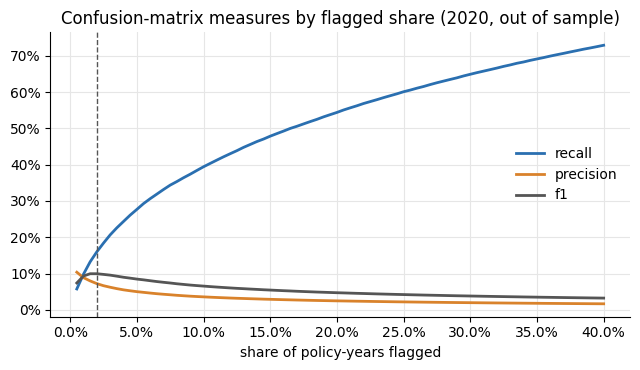

In [10]:
# Step 4.2 Learn on 2014-2019, stop early on 2020: the number of trees; then the F1-best flagged share on 2020
last = years_train.max()
inner, outer = years_train < last, years_train == last
t0 = time.time()
booster_inner, BEST_ROUNDS, rec_inner = fit(PARAMS, X_train[inner], y_train[inner], w_train[inner],
                                            X_train[outer], y_train[outer], w_train[outer])
s_inner = predict(booster_inner, X_train[outer], BEST_ROUNDS)
y_inner, w_inner = y_train[outer].to_numpy(), w_train[outer]
print(f"best number of trees: {BEST_ROUNDS} (recall in the riskiest {TOP_SHARE:.0%} of {last}: {rec_inner:.2%}) "
      f"in {(time.time() - t0) / 60:.1f} min")
del booster_inner

# F1 at every flagged share from 0.5% to 40% (weighted, so the shares are shares of all 2020 policy-years)
rate_2020 = np.average(y_inner, weights=w_inner)
scan = []
for share in np.arange(0.005, 0.4001, 0.005):
    rec = recall_at_share(s_inner, y_inner, w_inner, share)
    prec = rec * rate_2020 / share                    # TP / flagged, with TP = recall x claims and flagged = share x rows
    scan.append({"flagged_share": share, "recall": rec, "precision": prec, "f1": 2 * prec * rec / (prec + rec) if prec + rec else 0})
scan = pd.DataFrame(scan)
BEST_SHARE = float(scan.loc[scan["f1"].idxmax(), "flagged_share"])
print(f"F1-best flagged share on {last}: {BEST_SHARE:.1%} (F1 {scan['f1'].max():.3f})")
if BEST_SHARE in (scan["flagged_share"].min(), scan["flagged_share"].max()):
    print("note: the best share is at the edge of the scan (0.5% to 40%); F1 may keep rising beyond it")

fig, ax = plt.subplots(figsize=(6.5, 3.8))
for col, color in [("recall", "#2a6fb0"), ("precision", "#d9822b"), ("f1", "#555555")]:
    ax.plot(scan["flagged_share"], scan[col], label=col, color=color, linewidth=2)
ax.axvline(BEST_SHARE, color="#555555", linestyle="--", linewidth=1)
ax.set(title=f"Confusion-matrix measures by flagged share ({last}, out of sample)", xlabel="share of policy-years flagged")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1)); ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False); ax.grid(color="#e6e6e6"); ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

#### 4.3 Fit on the full weighted training sample (2014–2020)
The final XGBoost model learns on every row of the weighted training sample with the setting from Step 4.1 and the number of trees from Step 4.2.

In [11]:
# Step 4.3 The final model on 2014-2020
t0 = time.time()
model, _, _ = fit(PARAMS, X_train, y_train, w_train, rounds=BEST_ROUNDS)
print(f"trained {BEST_ROUNDS} trees on {len(y_train):,} rows in {(time.time() - t0) / 60:.1f} min")

trained 1092 trees on 3,071,381 rows in 2.0 min


### Section 5. Out-of-time test results (OOT1, 2021–2022)

#### 5.1 Score the test split
Every test row (7.3M), chunk by chunk, with XGBoost and the segment rule. If the baseline's saved test predictions (`claim_baseline_logreg_test.parquet` from notebook 06a) are on this machine and cover the same rows, they are added for a like-for-like comparison.

**Check before reading the comparison:** the saved baseline predictions must come from the same 06a run as `reports/claim_baseline_logreg_*`. They did not match on 2026-11-17 (the saved model used `alpha` = 1e-4 and `eta0` = 0.01, the report 1e-6 and 0.001), so rerun 06a in full first. Step 5.2 also checks that the saved baseline model reproduces the saved predictions.

In [12]:
# Step 5.1 Score every test row (2021-2022), chunk by chunk; the validation split stays untouched until notebook 08
t0 = time.time()
parts = []
for k in range(N_CHUNKS):
    X, y, ids, _ = load_rows("test", where=chunk_filter(k))
    if len(y) == 0:
        continue
    parts.append(pd.DataFrame({
        "period_id": ids["period_id"].to_numpy(), "period_year": ids["period_year"].to_numpy(), "y": y.to_numpy(),
        COL: predict(model, to_tree_frame(X)),
        "zone_group": X["zone_group"].to_numpy(),
        "had_prior_claim": X["had_prior_claim"].fillna(0).astype(int).to_numpy(),
    }))
pred = pd.concat(parts, ignore_index=True)
del parts, X, y, ids

# The segment rule (a segment not seen in training gets the training claim rate)
pred = pred.merge(segment_rates[["zone_group", "had_prior_claim", "segment_rate"]], on=["zone_group", "had_prior_claim"], how="left")
pred["p_segment"] = pred.pop("segment_rate").fillna(full_rate)

# The logistic-regression baseline (notebook 06a), if its test predictions are here and cover every row
MODELS = {"segment rule": "p_segment"}
baseline_file = PROCESSED / "predictions" / "claim_baseline_logreg_test.parquet"
if baseline_file.exists():
    pred = pred.merge(pd.read_parquet(baseline_file, columns=["period_id", "p_logreg"]), on="period_id", how="left")
    if pred["p_logreg"].notna().all():
        MODELS["logistic regression (06a)"] = "p_logreg"
    else:
        print(f"baseline predictions miss {pred['p_logreg'].isna().sum():,} test rows: left out of the comparison")
        pred = pred.drop(columns="p_logreg")
else:
    print("no saved baseline predictions found: run notebook 06a first to compare with it")
MODELS["XGBoost"] = COL
print(f"scored {len(pred):,} test rows in {(time.time() - t0) / 60:.1f} min; claim rate {pred['y'].mean():.3%}")

scored 7,275,717 test rows in 1.2 min; claim rate 1.149%


#### 5.2 The cut-offs, set on the training years
A cut-off rule says what share of policy-years to flag. Each rule becomes a score cut-off **on each model's own training scores**, so the test outcomes are never used to choose it (as in notebook 06a, Step 5.4):
$$c_{q} = \text{quantile}_{1-q}\big(\{\text{score}_j\}_{j \in \text{train}}\big)$$

| Rule | Flagged share $q$ | Why |
|---|---|---|
| Riskiest 5%, 10%, 20% | 0.05, 0.10, 0.20 | The same rules as 06a, for a direct comparison |
| F1-best | `BEST_SHARE` from Step 4.2 (chosen on 2020) | The share that balances precision and recall best |
| Default 0.5 | – (cut-off 0.5) | Shown to make the point that it flags almost nobody for a 1% event |

The training scores come from a 1M-row random sample of all training rows (not the weighted sample). For the baseline, the saved 06a model scores the same rows; it is used only if it reproduces the saved test predictions. Because the cut-offs come from training, the share flagged in the test years may differ from $q$: that difference is itself a check that the scores are stable over time.

In [13]:
# Step 5.2 Cut-offs from each model's TRAINING scores (1M random training rows), for every rule
import joblib

RULES = {f"riskiest {s:.0%}": s for s in FLAG_SHARES}
RULES[f"F1-best ({BEST_SHARE:.1%}, chosen on {last})"] = BEST_SHARE
RULES["p >= 0.5 (default)"] = None

X_s, _, _, _ = load_rows("train", sample_rows=1_000_000)
train_scores = {COL: predict(model, to_tree_frame(X_s))}
# The segment rule: weighted by the number of training rows in each segment
seg_quantile = lambda q: weighted_quantile(segment_rates["segment_rate"], q, segment_rates["train_rows"])

# The baseline: score the same training rows with the saved 06a model, if it reproduces the saved test predictions
if "p_logreg" in pred:
    base_model_file = PROCESSED / "models" / "claim_baseline_logreg.joblib"
    ok = False
    if base_model_file.exists():
        saved = joblib.load(base_model_file)
        X_c, _, ids_c, _ = load_rows("test", sample_rows=1000)
        p_c = saved["model"].predict_proba(saved["preprocess"].transform(X_c[saved["features"]]))[:, 1]
        ok = np.allclose(p_c, ids_c[["period_id"]].merge(pred[["period_id", "p_logreg"]], on="period_id")["p_logreg"])
        if ok:
            train_scores["p_logreg"] = saved["model"].predict_proba(saved["preprocess"].transform(X_s[saved["features"]]))[:, 1]
    if not ok:
        print("the saved 06a model does not reproduce the saved test predictions (or is missing): baseline left out")
        del MODELS["logistic regression (06a)"]
        pred = pred.drop(columns="p_logreg")
del X_s

CUTS = {}
for name, col in MODELS.items():
    for rule, share in RULES.items():
        if share is None:
            cut = 0.5
        elif col == "p_segment":
            cut = seg_quantile(1 - share)
        else:
            cut = float(np.quantile(train_scores[col], 1 - share))
        CUTS[(name, rule)] = cut
pd.Series(CUTS, name="cut-off").unstack(0).style.format("{:.4f}")

/opt/homebrew/Cellar/jupyterlab/4.5.6_2/libexec/lib/python3.14/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator SimpleImputer from version 1.9.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/opt/homebrew/Cellar/jupyterlab/4.5.6_2/libexec/lib/python3.14/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.9.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/opt/homebrew/Cellar/jupyterlab/4.5.6_2/libexec/lib/python3.14/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpic

,XGBoost,logistic regression (06a),segment rule
"F1-best (2.0%, chosen on 2020)",0.1085,0.0494,0.0324
p >= 0.5 (default),0.5000,0.5000,0.5000
riskiest 10%,0.0219,0.0254,0.0140
riskiest 20%,0.0113,0.0179,0.0140
riskiest 5%,0.0441,0.0344,0.0297


#### 5.3 Confusion matrices on the test years
Every model × rule, for 2021–2022 together and for each year (2022 has Hurricane Ian and is the first full year of Risk Rating 2.0, so a model that only wins on average is not enough).

**How to read it:** with a claim rate of about 1%, a precision of 3–4% is a **lift of about 3**: the flagged group claims three times as often as an average policy-year. Accuracy is high for every rule only because most policy-years have no claim; it is shown, but **read precision, recall, F1 and lift**. At the same flagged share, the model with more TP is better on all four.

**Check the share flagged first.** The cut-offs come from the training years. If the test years look less risky to a model (fewer recent storms, a lower claim rate), its scores drop and "the riskiest 10% in train" flags fewer than 10% of the test policy-years, sometimes far fewer. Models that flag different shares can't be compared on recall or precision alone; Step 5.4 compares them at the **same** share.

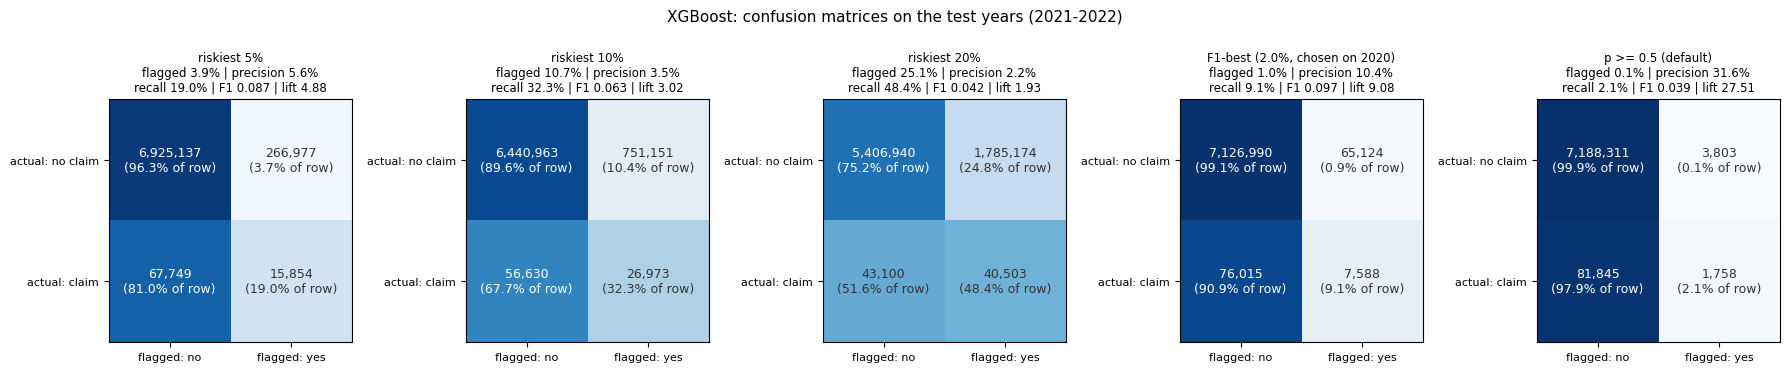

model,rule,cut_off,flagged_share,TP,FP,FN,TN,accuracy,precision,recall,f1,lift
segment rule,riskiest 5%,0.0297,8.1%,"14,081","575,812","69,522","6,616,302",0.911,2.39%,16.8%,0.042,2.08
segment rule,riskiest 10%,0.0140,53.1%,"70,051","3,793,442","13,552","3,398,672",0.477,1.81%,83.8%,0.035,1.58
segment rule,riskiest 20%,0.0140,53.1%,"70,051","3,793,442","13,552","3,398,672",0.477,1.81%,83.8%,0.035,1.58
segment rule,"F1-best (2.0%, chosen on 2020)",0.0324,2.5%,"3,241","181,327","80,362","7,010,787",0.964,1.76%,3.9%,0.024,1.53
segment rule,p >= 0.5 (default),0.5000,0.0%,0,0,"83,603","7,192,114",0.989,0.00%,0.0%,0.000,0.00
logistic regression (06a),riskiest 5%,0.0344,2.7%,"8,126","188,925","75,477","7,003,189",0.964,4.12%,9.7%,0.058,3.59
logistic regression (06a),riskiest 10%,0.0254,5.9%,"15,064","411,039","68,539","6,781,075",0.934,3.54%,18.0%,0.059,3.08
logistic regression (06a),riskiest 20%,0.0179,13.5%,"27,027","957,585","56,576","6,234,529",0.861,2.74%,32.3%,0.051,2.39
logistic regression (06a),"F1-best (2.0%, chosen on 2020)",0.0494,1.0%,"3,486","70,839","80,117","7,121,275",0.979,4.69%,4.2%,0.044,4.08
logistic regression (06a),p >= 0.5 (default),0.5000,0.0%,0,0,"83,603","7,192,114",0.989,0.00%,0.0%,0.000,0.00


In [14]:
# Step 5.3 Confusion matrices: every model x rule, for 2021-2022 and each test year
rows = []
for scope, part in [("2021-2022", pred), *[(str(y), g) for y, g in pred.groupby("period_year")]]:
    for name, col in MODELS.items():
        for rule in RULES:
            rows.append({"scope": scope, "model": name, "rule": rule, "cut_off": CUTS[(name, rule)],
                         **confusion(part["y"], part[col], CUTS[(name, rule)])})
cm_table = pd.DataFrame(rows)

# The confusion matrices of XGBoost on 2021-2022, one panel per rule
panels = cm_table[(cm_table["scope"] == "2021-2022") & (cm_table["model"] == "XGBoost")].reset_index(drop=True)
fig, axes = plt.subplots(1, len(panels), figsize=(3.6 * len(panels), 3.9))
for ax, (_, r) in zip(axes, panels.iterrows()):
    mat = np.array([[r["TN"], r["FP"]], [r["FN"], r["TP"]]])
    ax.imshow(mat / np.maximum(mat.sum(axis=1, keepdims=True), 1), cmap="Blues", vmin=0, vmax=1)
    for a in range(2):
        for b in range(2):
            share = mat[a, b] / max(mat[a].sum(), 1)
            ax.text(b, a, f"{mat[a, b]:,}\n({share:.1%} of row)", ha="center", va="center", fontsize=9,
                    color="white" if share > 0.6 else "#333333")
    ax.set_xticks([0, 1], ["flagged: no", "flagged: yes"], fontsize=8)
    ax.set_yticks([0, 1], ["actual: no claim", "actual: claim"], fontsize=8)
    ax.set_title(f"{r['rule']}\nflagged {r['flagged_share']:.1%} | precision {r['precision']:.1%}\n"
                 f"recall {r['recall']:.1%} | F1 {r['f1']:.3f} | lift {r['lift']:.2f}", fontsize=8.5)
fig.suptitle("XGBoost: confusion matrices on the test years (2021-2022)", fontsize=11)
plt.tight_layout()
plt.savefig(REPORTS / f"fig_{NAME}_confusion.png", dpi=150)
plt.show()

# The main table: 2021-2022, every model and rule
cm_fmt = {"cut_off": "{:.4f}", "flagged_share": "{:.1%}", "TP": "{:,}", "FP": "{:,}", "FN": "{:,}", "TN": "{:,}",
          "accuracy": "{:.3f}", "precision": "{:.2%}", "recall": "{:.1%}", "f1": "{:.3f}", "lift": "{:.2f}"}
display(cm_table[cm_table["scope"] == "2021-2022"].drop(columns="scope").style.format(cm_fmt).hide(axis="index"))

# Each test year separately: recall, precision, F1 and lift per model and rule
by_scope = cm_table[cm_table["scope"] != "2021-2022"].pivot_table(
    index=["rule", "model"], columns="scope", values=["flagged_share", "recall", "precision", "f1", "lift"], sort=False)
by_scope.style.format("{:.3f}")

#### 5.4 Precision and recall by flagged share
One confusion matrix per flagged share, from 1% to 40% of the test policy-years (ranked by each model's own test scores): the share of claims caught (recall) and the claim rate of the flagged group (precision). A curve that lies **above** another catches more claims for the same number of flagged policy-years. This view does not depend on any cut-off rule.

This is also how the model would be used in practice: score the policies coming up for renewal and flag the riskiest 5%, 10% or 20% **of that batch**. The ranking uses only the scores, never the test outcomes. The table gives the full confusion-matrix measures at 5%, 10% and 20% for every model, at exactly the same flagged share. The segment rule gives the same score to a whole segment, so to flag an exact share it takes part of a segment; those policy-years are taken in row order, which is effectively at random.

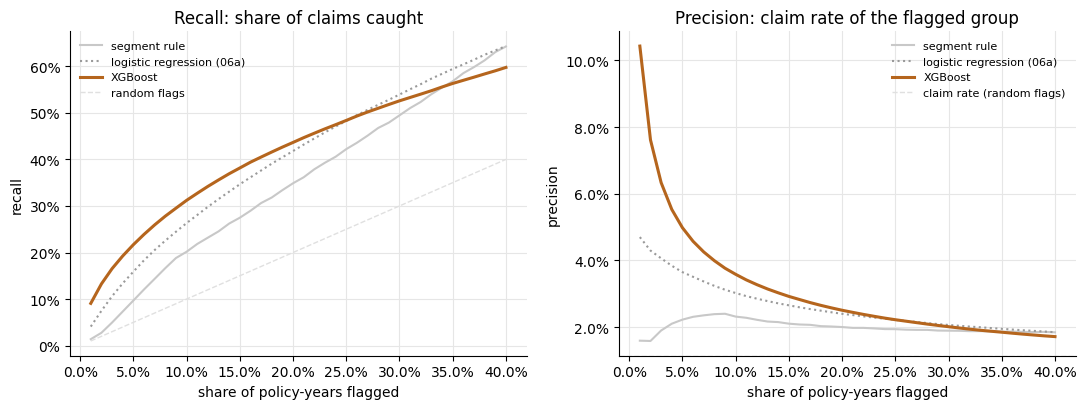

model,flagged_share,recall,precision,f1,lift
segment rule,5%,9.7%,2.23%,0.036,1.94
segment rule,10%,20.2%,2.32%,0.042,2.02
segment rule,20%,34.9%,2.00%,0.038,1.74
logistic regression (06a),5%,15.9%,3.65%,0.059,3.18
logistic regression (06a),10%,26.3%,3.02%,0.054,2.63
logistic regression (06a),20%,41.8%,2.40%,0.045,2.09
XGBoost,5%,21.7%,4.98%,0.081,4.34
XGBoost,10%,31.2%,3.59%,0.064,3.12
XGBoost,20%,43.6%,2.51%,0.047,2.18


In [15]:
# Step 5.4 Recall and precision at every flagged share from 1% to 40% (each point is one confusion matrix)
from matplotlib.ticker import PercentFormatter

shares = np.arange(0.01, 0.401, 0.01)
claim_rate = pred["y"].mean()
STYLE = {"p_segment": dict(color="#c8c8c8", linewidth=1.5), "p_logreg": dict(color="#9a9a9a", linewidth=1.5, linestyle=":"),
         COL: dict(color="#b5651d", linewidth=2.2)}
def recall_curve(score, y):
    '''Recall at every share in `shares`, from one sort of the scores.'''
    caught = np.cumsum(np.asarray(y)[np.argsort(-np.asarray(score), kind="stable")])
    return [caught[max(int(round(s * len(caught))) - 1, 0)] / caught[-1] for s in shares]
curve = {name: recall_curve(pred[col], pred["y"]) for name, col in MODELS.items()}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
for name, col in MODELS.items():
    rec = np.array(curve[name])
    ax1.plot(shares, rec, label=name, **STYLE[col])
    ax2.plot(shares, rec * claim_rate / shares, label=name, **STYLE[col])
ax1.plot(shares, shares, color="#e0e0e0", linestyle="--", linewidth=1, label="random flags")
ax2.axhline(claim_rate, color="#e0e0e0", linestyle="--", linewidth=1, label="claim rate (random flags)")
ax1.set(title="Recall: share of claims caught", xlabel="share of policy-years flagged", ylabel="recall")
ax2.set(title="Precision: claim rate of the flagged group", xlabel="share of policy-years flagged", ylabel="precision")
for ax in (ax1, ax2):
    ax.xaxis.set_major_formatter(PercentFormatter(1)); ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.legend(frameon=False, fontsize=8); ax.spines[["top", "right"]].set_visible(False)
    ax.grid(color="#e6e6e6"); ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(REPORTS / f"fig_{NAME}_recall_precision_by_share.png", dpi=150)
plt.show()

# Confusion-matrix measures when each model flags exactly 5%, 10% and 20% of the test policy-years (its own ranking)
rows = []
for name in MODELS:
    for s in [0.05, 0.10, 0.20]:
        rec = curve[name][int(round(s * 100)) - 1]
        prec = rec * claim_rate / s
        rows.append({"model": name, "flagged_share": s, "recall": rec, "precision": prec,
                     "f1": 2 * prec * rec / (prec + rec) if prec + rec else 0.0, "lift": prec / claim_rate})
same_share = pd.DataFrame(rows)
same_share.style.format({"flagged_share": "{:.0%}", "recall": "{:.1%}", "precision": "{:.2%}", "f1": "{:.3f}",
                         "lift": "{:.2f}"}).hide(axis="index")

#### 5.5 ROC curve
Each point of the ROC curve is one confusion matrix: the share of claims caught (TPR = recall) against the share of other policy-years wrongly flagged (FPR = FP / (FP + TN)), for every possible cut-off. The **AUC** (area under the curve) summarizes the whole curve: 0.5 = random flags, 1.0 = perfect. The dots mark the rules of Step 5.2 for XGBoost.

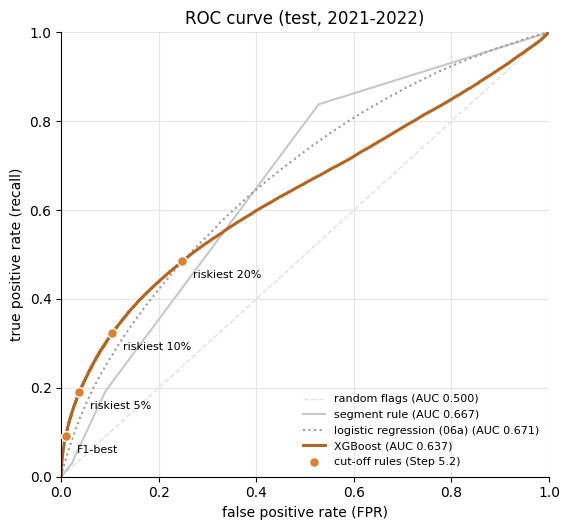

In [16]:
# Step 5.5 ROC curves, with the cut-off rules of Step 5.2 marked for XGBoost
from sklearn.metrics import roc_auc_score, roc_curve

fig, ax = plt.subplots(figsize=(5.8, 5.4))
ax.plot([0, 1], [0, 1], color="#e0e0e0", linewidth=1, linestyle="--", label="random flags (AUC 0.500)")
for name, col in MODELS.items():
    fpr, tpr, _ = roc_curve(pred["y"], pred[col])
    ax.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(pred['y'], pred[col]):.3f})", **STYLE[col])
rules = cm_table[(cm_table["scope"] == "2021-2022") & (cm_table["model"] == "XGBoost") & (cm_table["rule"] != "p >= 0.5 (default)")]
ax.scatter(rules["FP"] / (rules["FP"] + rules["TN"]), rules["recall"], color="#d9822b", s=50, zorder=3,
           edgecolor="white", label="cut-off rules (Step 5.2)")
for _, r in rules.iterrows():
    ax.annotate(r["rule"].split(" (")[0], (r["FP"] / (r["FP"] + r["TN"]), r["recall"]),
                textcoords="offset points", xytext=(8, -12), fontsize=8)
ax.set(title="ROC curve (test, 2021-2022)", xlabel="false positive rate (FPR)", ylabel="true positive rate (recall)",
       xlim=(0, 1), ylim=(0, 1))
ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.spines[["top", "right"]].set_visible(False); ax.grid(color="#e6e6e6"); ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(REPORTS / f"fig_{NAME}_roc.png", dpi=150)
plt.show()

### Section 6. Feature importance and SHAP: why policy-years are flagged

#### 6.1 Which features drive the score
Two views:
- **Gain importance:** the total improvement from all the splits on a feature, over every tree. Quick, but it favours features with many distinct values.
- **Mean |SHAP|:** for each policy-year, SHAP splits the model's raw score into one contribution per feature, which add up exactly:
$$F(\mathbf{x}_i) = \phi_0 + \sum_{k} \phi_{ik}$$
$\phi_0$ is the average score and $\phi_{ik}$ is how much feature $k$ moves policy-year $i$ up or down the ranking. The mean of $|\phi_{ik}|$ ranks the features by how much they move the scores, and so by how much they decide **who gets flagged**. XGBoost computes exact tree SHAP itself (`pred_contribs=True`), so no extra package is needed.

We use a random sample of 200,000 **test** policy-years. These show what the model uses, **not causes**, and a feature that matters only in the training years is a warning sign.

SHAP values add up to the model's raw score: largest gap 2.19e-05 (expect about 0)


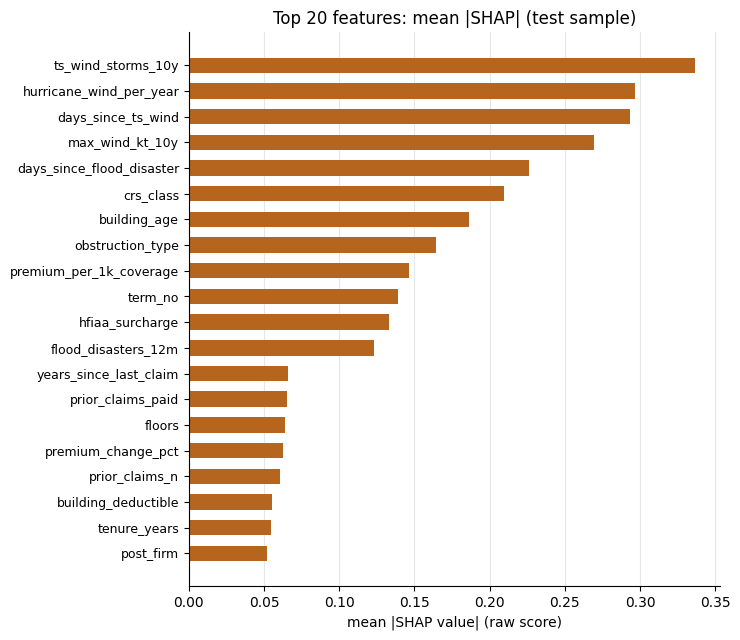

,mean_abs_shap,gain,gain_share,kind
ts_wind_storms_10y,0.3364,"644,771",5.0%,number
hurricane_wind_per_year,0.2966,"1,938,484",15.0%,number
days_since_ts_wind,0.2935,"2,090,438",16.1%,number
max_wind_kt_10y,0.2693,"2,548,970",19.7%,number
days_since_flood_disaster,0.2263,"1,367,918",10.6%,number
crs_class,0.2094,"830,830",6.4%,category
building_age,0.1862,"213,430",1.6%,number
obstruction_type,0.1647,"218,439",1.7%,category
premium_per_1k_coverage,0.1465,"452,131",3.5%,number
term_no,0.1392,"65,818",0.5%,number


In [17]:
# Step 6.1 Gain importance and mean |SHAP| on 200,000 test policy-years
X_shap, _, _, _ = load_rows("test", sample_rows=200_000, seed=SEED + 1)
X_shap = to_tree_frame(X_shap)
importance_gain = pd.Series(model.get_score(importance_type="total_gain")).reindex(FEATS).fillna(0)
contrib = model.predict(dmatrix(X_shap), pred_contribs=True)       # n x (features + 1); last column = phi_0
shap = pd.DataFrame(contrib[:, :-1], columns=FEATS)
p_shap = predict(model, X_shap)
check_sum = np.abs(contrib.sum(axis=1) - np.log(p_shap / (1 - p_shap))).max()
print(f"SHAP values add up to the model's raw score: largest gap {check_sum:.2e} (expect about 0)")

importance = pd.DataFrame({"mean_abs_shap": shap.abs().mean(), "gain": importance_gain.reindex(FEATS).fillna(0)})
importance["gain_share"] = importance["gain"] / importance["gain"].sum()
importance["kind"] = ["number" if f in NUMS else "category" if f in CATS else "flag" for f in importance.index]
importance = importance.sort_values("mean_abs_shap", ascending=False)

top = importance.head(20)[::-1]
fig, ax = plt.subplots(figsize=(7.5, 6.5))
ax.barh(top.index, top["mean_abs_shap"], color="#b5651d", height=0.6)
ax.set(title="Top 20 features: mean |SHAP| (test sample)", xlabel="mean |SHAP value| (raw score)")
ax.tick_params(axis="y", labelsize=9)
ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="x", color="#e6e6e6"); ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(REPORTS / f"fig_{NAME}_shap_importance.png", dpi=150)
plt.show()
importance.head(20).style.format({"mean_abs_shap": "{:.4f}", "gain": "{:,.0f}", "gain_share": "{:.1%}"})

#### 6.2 How the top numbers move the score
For the four most important **numbers**, each dot is one policy-year: its value (x) against its SHAP contribution (y). A rising cloud means more of the feature pushes the policy-year towards being flagged; a curve or a jump is the non-linearity that logistic regression could not show. The vertical spread at one value comes from interactions with other features.

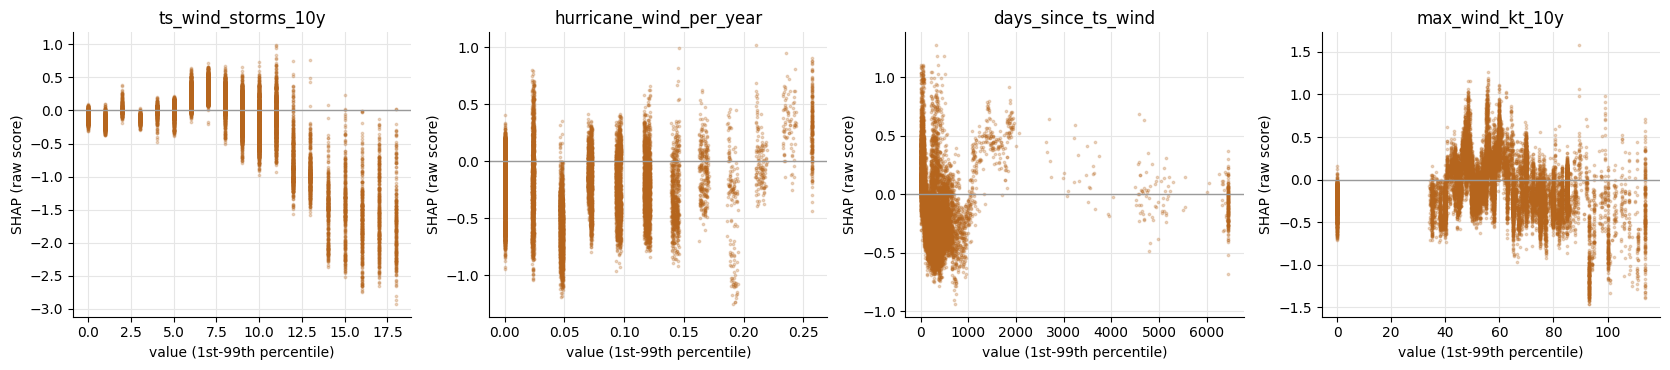

In [18]:
# Step 6.2 SHAP dependence for the four most important numbers (20,000 dots each)
top_nums = [f for f in importance.index if f in NUMS][:4]
idx = np.random.default_rng(SEED).choice(len(X_shap), size=min(20_000, len(X_shap)), replace=False)
fig, axes = plt.subplots(1, len(top_nums), figsize=(4.2 * len(top_nums), 3.8), squeeze=False)
for ax, f in zip(axes[0], top_nums):
    x = X_shap[f].to_numpy("float64")[idx]
    lo, hi = np.nanquantile(x, [0.01, 0.99])
    ax.scatter(np.clip(x, lo, hi), shap[f].to_numpy()[idx], s=3, alpha=0.25, color="#b5651d", rasterized=True)
    ax.axhline(0, color="#9a9a9a", linewidth=1)
    ax.set(title=f, xlabel="value (1st-99th percentile)", ylabel="SHAP (raw score)")
    ax.spines[["top", "right"]].set_visible(False); ax.grid(color="#e6e6e6"); ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(REPORTS / f"fig_{NAME}_shap_dependence.png", dpi=150)
plt.show()

### Section 7. Save

#### 7.1 Save the model and results
- `data/processed/models/`: the booster in XGBoost's own format, and a `.joblib` bundle with the booster, the preprocessing (medians, 99 fill, category levels) and the **cut-offs of every rule**, so notebook 08 flags new rows exactly as here.
- `data/processed/predictions/claim_xgb_test.parquet`: the test scores and flags row by row (and the segment rule), so notebook 08 can compare models without retraining.
- `reports/`: confusion matrices (every model, rule and year), cut-offs, recall by flagged share, tuning results, feature importance and the run record (JSON).

The last line reloads the saved model and checks it gives the same scores.

In [19]:
# Step 7.1 Save the model, the test scores and flags, and the results
import json
from datetime import datetime

MODEL_DIR = PROCESSED / "models"
PRED_DIR = PROCESSED / "predictions"
for d in (MODEL_DIR, PRED_DIR):
    d.mkdir(parents=True, exist_ok=True)

MODEL_CUTS = {rule: CUTS[("XGBoost", rule)] for rule in RULES}
model.save_model(str(MODEL_DIR / f"{NAME}.json"))                                 # XGBoost JSON format
joblib.dump({"booster": model, "trees": BEST_ROUNDS, "prep": PREP, "cut_offs": MODEL_CUTS, "rules": RULES,
             "features": FEATS, "numbers": NUMS, "categories": CATS, "flags": FLAGS}, MODEL_DIR / f"{NAME}.joblib")

flags = pd.DataFrame({f"flag_{s:.0%}".replace("%", "pct"): (pred[COL] >= MODEL_CUTS[f"riskiest {s:.0%}"]).astype("int8")
                      for s in FLAG_SHARES})
flags["flag_f1_best"] = (pred[COL] >= MODEL_CUTS[next(r for r in RULES if r.startswith("F1-best"))]).astype("int8")
keep = ["period_id", "period_year", "y", COL, "p_segment"] + (["p_logreg"] if "p_logreg" in pred else [])
pd.concat([pred[keep], flags], axis=1).to_parquet(PRED_DIR / f"{NAME}_test.parquet", index=False)

cm_table.to_csv(REPORTS / f"{NAME}_test_confusion.csv", index=False)
pd.Series(CUTS, name="cut_off").rename_axis(["model", "rule"]).to_csv(REPORTS / f"{NAME}_cut_offs.csv")
pd.DataFrame(curve, index=pd.Index(shares.round(2), name="flagged_share")).to_csv(REPORTS / f"{NAME}_test_recall_by_share.csv")
same_share.to_csv(REPORTS / f"{NAME}_test_same_share.csv", index=False)
scan.to_csv(REPORTS / f"{NAME}_f1_scan_{last}.csv", index=False)
tuning.to_csv(REPORTS / f"{NAME}_tuning.csv", index=False)
importance.to_csv(REPORTS / f"{NAME}_feature_importance.csv")

main = cm_table[(cm_table["scope"] == "2021-2022") & (cm_table["model"] == "XGBoost")].set_index("rule")
run = {
    "model": NAME, "library": "XGBoost", "library_version": xgb.__version__, "target": TARGET, "view": "confusion matrix only",
    "saved_at": datetime.now().isoformat(timespec="seconds"),
    "train_split": f"train (2014-2020): every claim + {NEG_RATE:.0%} of the other policy-years, weighted back",
    "scored_on": "test (2021-2022)", "quick_run": QUICK_RUN, "states": STATES or "all",
    "features_used": FEATS, "features_excluded": list(EXCLUDE),
    "neg_rate": NEG_RATE, "train_rows": int(len(y_train)), "tune_rows": int(min(TUNE_ROWS, len(y_train))),
    "tuning_metric": f"mean recall in the riskiest {TOP_SHARE:.0%} over the rolling folds", "n_trials": N_TRIALS,
    "params": {k: (v.item() if hasattr(v, "item") else v) for k, v in PARAMS.items()}, "trees": int(BEST_ROUNDS),
    "f1_best_share": BEST_SHARE, "f1_best_share_chosen_on": int(last), "cut_offs": MODEL_CUTS, "seed": SEED,
    "test_2021_2022": main.drop(columns=["scope", "model"]).to_dict(orient="index"),
}
(REPORTS / f"{NAME}_run.json").write_text(json.dumps(run, indent=2, default=float))

# Check: the saved model loads and gives the same scores
reloaded = xgb.Booster(); reloaded.load_model(str(MODEL_DIR / f"{NAME}.json"))
X_check, _, _, _ = load_rows("test", sample_rows=1000)
X_check = to_tree_frame(X_check)
same = np.allclose(reloaded.predict(dmatrix(X_check)), predict(model, X_check))
print(f"saved {NAME} model, cut-offs, test scores and flags, confusion matrices, recall by share, tuning, importance "
      f"and run record; reload gives the same scores: {same}")

saved claim_xgb model, cut-offs, test scores and flags, confusion matrices, recall by share, tuning, importance and run record; reload gives the same scores: True


### Section 8. Our findings
Fill in after a full run (`QUICK_RUN = False`).

- **Riskiest 5/10/20% against the segment rule and the baseline (Step 5.3):** ... (precision, recall, F1 and lift for 2021–2022; how many more claims XGBoost catches at the same flagged share)
- **2021 against 2022 (Step 5.3):** ... (does XGBoost still beat the segment rule in 2022, the year of Ian and Risk Rating 2.0?)
- **F1-best rule (Steps 4.2, 5.3):** ... (the share chosen on 2020, and the share it actually flags in the test years)
- **Share actually flagged (Step 5.3):** ... (does each rule flag about the intended share in 2021 and 2022, or do the scores drift?)
- **Same flagged share and ROC (Steps 5.4–5.5):** ... (precision, recall, F1 and lift at exactly 5/10/20%; is XGBoost's curve above the others at every share?)
- **Main drivers (Section 6):** ... (do they agree with notebook 05? any feature that only works in the training years?)
- **Against LightGBM (`07a_lightgbm_claim`) and random forest (`07a_random_forest_claim`):** ... (fill in once all three have run)